# Day 2 - Supervised learning practical tasks
***
These tasks cover linear regression, logistic regression, decision trees, model evaluation and regularization.

## Regression models

You will use [Advertising](https://www.kaggle.com/purbar/advertising-data) Dataset. The dataset contains statistics about the sales of a product in 200 different markets, together with advertising budgets in each of these markets for different media channels: TV, radio and newspaper.
#### Your task will be to:
1. Write evaluation functions (MAE, MSE, SSE, RMSE, MAPE, R2).
2. Analyze the correlation matrix.
3. Predict sales values using linear regression.
4. Evaluate model with written statistical explanatory variables.
5. Perform cross-validation (k-fold).
6. Compare your regression model to a reduced model by removing one of the features.
7. Compare your regression model to regularization models.

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

In [390]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge
from sklearn.linear_model import ElasticNet

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_auc_score
from sklearn.metrics import RocCurveDisplay

#### ---- For Function testing ----

In [391]:
y_true = [2, 4, 6]
y_pred = [5, 7, 3]

### 1. Create statistical evaluation functions for regression models

#### 1.1 Create a function that calculates mean absolute error (MAE)

\begin{equation}
MAE = \frac{1}{n} \sum_{i=1}^{n} \left| y_i - \hat{y}_i\right|
\end{equation}

In [392]:
def mae(y_true: list[float], y_pred: list[float]) -> float:
    return np.mean(np.abs(np.array(y_true) - np.array(y_pred)))  

In [393]:
# Testing
print(mae(y_true, y_pred))

3.0


#### 1.2 Create a function that calculates mean squared error (MSE)

\begin{equation}
MSE = \frac{1}{n}\cdot SSE
\end{equation}

\begin{equation}
SSE = \sum_{i=1}^n(y_i - \hat{y}_i)^2
\end{equation}

In [394]:
def sse(y_true: list[float], y_pred: list[float]) -> float:
    return np.sum((np.array(y_true) - np.array(y_pred)) ** 2)
     
def mse(y_true: list[float], y_pred: list[float]) -> float:
    return sse(y_true, y_pred) / len(y_true)


In [395]:
# Testing
print(mse(y_true, y_pred))

9.0


#### 1.3 Create a function that calculates root mean squared error (RMSE)

\begin{equation}
RMSE = \sqrt{MSE}
\end{equation}

In [396]:
def rmse(y_true: list[float], y_pred: list[float]) -> float:
    return np.sqrt(mse(y_true, y_pred))

In [397]:
# Testing
print(rmse(y_true, y_pred))

3.0


#### 1.4 Create a function that calculates mean absolute percentage error (MAPE)

\begin{equation}
MAPE = \frac{100}{n} \sum_{i=1}^n \left| \frac{y_i - \hat{y}_i}{y_i} \right|
\end{equation}

In [398]:
def mape(y_true: list[float], y_pred: list[float]) -> float:
    return np.mean(np.abs((np.array(y_true) - np.array(y_pred)) / np.array(y_true)) * 100)

In [399]:
# Testing
print(mape(y_true, y_pred))

91.66666666666667


#### 1.5 Create a function that calculates coefficient of determination $R^2$ using formula

\begin{equation}
R^2 = \frac{SST-SSE}{SST}
\end{equation}

\begin{equation}
SST = \sum_{i=1}^n (y_i - \bar{y})^2
\end{equation}


In [400]:
def sst(y_true: list[float]) -> float:
    mean = np.mean(np.array(y_true))
    return np.sum((np.array(y_true) - mean) ** 2)

def r_squared(y_true: list[float], y_pred: list[float]) -> float:
    sst_value = sst(y_true)
    return (sst_value - sse(y_true, y_pred)) / sst_value


In [401]:
# Testing
print(r_squared(y_true, y_pred))

-2.375


### 2 Use Linear regression model to make predictions and evaluate it with above developed functions. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling - split the data in target variable and features.

In [402]:
df = pd.read_csv('advertising.csv', index_col=0)

In [403]:
X = df.drop('Sales', axis=1)
y = df['Sales']

#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

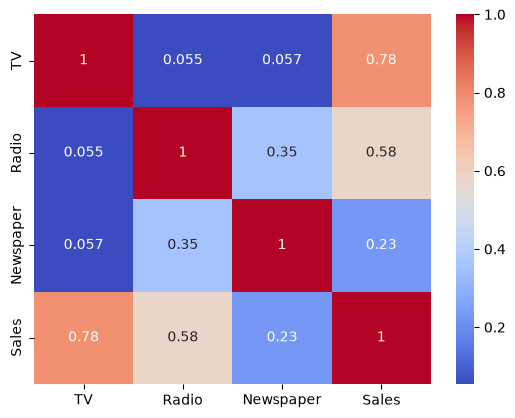

In [404]:
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.show()

#### ---- Observations ----
Correlation with the target variable `Sales` is positively moderate with the `TV` and `Radio` while TV is has the highest correlation.

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler).

In [405]:
scaler = StandardScaler()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=1/3, random_state=17)

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

#### 2.4 Fit linear regression model, generate predictions and print regression coefficients $b_0$ and $b_1$.

In [406]:
model = LinearRegression(fit_intercept=True)
model.fit(X_train_scaled, y_train)
print(model.intercept_) # b0
print(model.coef_) # b1

14.033082706766919
[ 3.96944495  2.88755129 -0.07026761]


In [407]:
y_pred = model.predict(X_test_scaled)

#### 2.5 Evaluate created model with above functions

In [408]:
mse_model1 = mse(y_test, y_pred)

print("MAE score:", mae(y_test, y_pred))
print("MSE score:", mse_model1)
print("RMSE score:", rmse(y_test, y_pred))
print("MAPE score:", mape(y_test, y_pred))
print("R^2 score:", r_squared(y_test, y_pred))

MAE score: 1.3020903541638358
MSE score: 3.3984306357936913
RMSE score: 1.8434832887210264
MAPE score: 18.625877945619205
R^2 score: 0.8526980892477296


#### 2.6 Perform k-fold cross-validation $(k=10)$ and print the mean $R^2$ score to get an overall performance metric.

Please use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [r2](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules) score.

In [409]:
scores = cross_val_score(model, X_train_scaled, y_train, cv=10, scoring='r2')

print("Overall performance metric:", scores.mean())

Overall performance metric: 0.8984335594122996


#### 2.7. Drop one of the three variables (TV, Radio or Newspaper) and create another model, evaluate it and compare to the first model.

In [410]:
X2 = X.copy().drop('Newspaper', axis=1)
X_train, X_test, y_train, y_test = train_test_split(
    X2, y, test_size=1/3, random_state=17)

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

model2 = LinearRegression(fit_intercept=True)
model2.fit(X_train_scaled, y_train)
y2_pred = model2.predict(X_test_scaled)

mse_model2 = mse(y_test, y2_pred)

scores2 = cross_val_score(
    model2,
    X_train_scaled,
    y_train,
    cv=10,
    scoring='r2'
)

In [411]:
print("MAE score:", mae(y_test, y2_pred))
print("MSE score:", mse_model2)
print("RMSE score:", rmse(y_test, y2_pred))
print("MAPE score:", mape(y_test, y2_pred))
print("R^2 score:", r_squared(y_test, y2_pred))

MAE score: 1.296271164998091
MSE score: 3.3824270060799257
RMSE score: 1.839137571276256
MAPE score: 18.554278507504968
R^2 score: 0.8533917521434735


In [412]:
print("Overall performance metric of the first model:", scores.mean())
print("Overall performance metric of the second model:", scores2.mean())

Overall performance metric of the first model: 0.8984335594122996
Overall performance metric of the second model: 0.899231443558263


### 3. Use regularization models with regularization strength `alpha=1` and compare $MSE$ values with previous models.

#### 3.1 Lasso regression

In [413]:
lasso = Lasso(alpha=1)
lasso.fit(X_train, y_train)
y_pred = lasso.predict(X_test)

mse_lasso = mse(y_test, y_pred)
print(f"Mean Squared Error: {mse_lasso}")

Mean Squared Error: 3.4051369604676696


#### 3.2 Ridge regression

In [414]:
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
y_pred = ridge.predict(X_test)

mse_ridge = mse(y_test, y_pred)
print("Mean Squared Error:", mse_ridge)

Mean Squared Error: 3.4140254068899307


#### 3.3 Elastic net regression

Use any `l1_ratio` of your choice.


In [415]:
elastic_net = ElasticNet(alpha=1.0, l1_ratio=0.5)
elastic_net.fit(X_train, y_train)

y_pred = elastic_net.predict(X_test)
mse_elastic = mse(y_test, y_pred)

In [416]:
print("Mean Squared Error of model1:", mse_model1)
print("Mean Squared Error of model2:", mse_model2)
print("Mean Squared Error of lasso model:", mse_lasso)
print("Mean Squared Error of ridge model:", mse_ridge)
print("Mean Squared Error of elastic net model:", mse_elastic)

Mean Squared Error of model1: 3.3984306357936913
Mean Squared Error of model2: 3.3824270060799257
Mean Squared Error of lasso model: 3.4051369604676696
Mean Squared Error of ridge model: 3.4140254068899307
Mean Squared Error of elastic net model: 3.407476168218169


#### 3.4 Make conclusions

Model2 performed the best. Regularizations did not improve performance but the diffences were relatively small meaning that in this case the simplest model (model2) should be used.

## Classification models

You will use [Diabetes](https://www.kaggle.com/uciml/pima-indians-diabetes-database) dataset. The dataset includes data from 768 women with several medical predictor variables and one target variable. The classification goal is to predict whether or not the patients in the dataset have diabetes.
#### Your task will be to:
1. Write evaluation functions (Accuracy, Precision, Recall, F1).
2. Predict whether or not a patient has diabetes using Logistic regression and Decision Tree Classification models
3. Evaluate both models with written statistical explanatory variables
4. Draw ROC curve and compute AUC
5. Perform cross-validation (k-fold)
6. Analyze the results

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

### 1. Write statistical evaluation functions for classification models

#### 1.1 Create a function that calculates accuracy

\begin{equation}
Accuracy = \frac{True Positive + True Negative}{True Positive + True Negative + False Positive + False Negative}
\end{equation}

In [417]:
def accuracy (tp: int, tn: int, fp: int, fn: int) -> float:
    return tp + tn / (tp + tn + fp + fn)

#### 1.2 Create a function that calculates precision

\begin{equation}
Precision = \frac{True Positive}{True Positive + False Positive}
\end{equation}

In [418]:
def precision (tp: int, fp: int) -> float:
    return tp / (tp + fp)

#### 1.3  Create a function that calculates recall

\begin{equation}
Recall = \frac{True Positive}{True Positive + False Negative}
\end{equation}

In [419]:
def recall (tp: int, fn: int) -> float:
    return tp / (tp + fn)

#### 1.4 Create a function that calculates $F1$ - score

\begin{equation}
F1 = 2\cdot \frac{Precision \cdot Recall}{Precision + Recall}
\end{equation}

In [420]:
def f1(tp: int, fp: int, fn: int) -> float:
    precision_v = precision(tp, fp)
    recall_v = recall(tp, fn)
    return 2 * (precision_v * recall_v / (precision_v + recall_v))

### 2. Use logistic regression to make prediction and evaluate it with above developed functions. Compute ROC and compute AUC. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling. Split the data in target variable and features.

Prepare dataset to use it for modelling (you should also replace 0 values in columns `Glucose`, `BloodPressure`,`SkinThickness`,`Insulin`,`BMI` with mean values).

In [421]:
df = pd.read_csv('diabetes.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [422]:
cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
for col in cols:
    mean_value = df.loc[df[col] != 0, col].mean()
    if col != 'BMI':
        df[col] = df[col].replace(0, round(mean_value, 0))
    else:
        df[col] = df[col].replace(0, round(mean_value, 1))
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,156,33.6,0.627,50,1
1,1,85,66,29,156,26.6,0.351,31,0
2,8,183,64,29,156,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [423]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']

#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

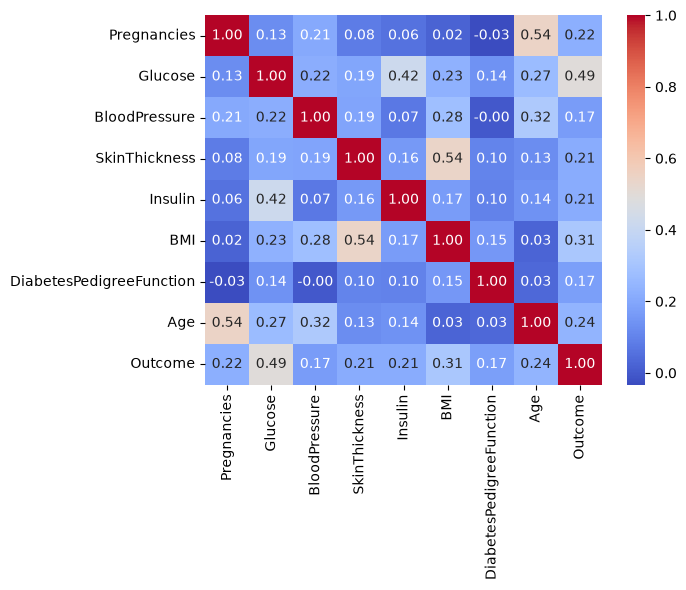

In [424]:
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

#### ---- Observation ----
The highest but moderate correlation is between Age and Pregnacies or BMI and SkinThickness which is 0.54. There are also a few weak Correlations. Most correlations are weak.

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

In [425]:
scaler = StandardScaler()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=1/3, random_state=17)

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

#### 2.4 Fit logistic regression model, generate predictions

In [426]:
logreg = LogisticRegression()
logreg.fit(X_train_scaled, y_train)
y_pred_log = logreg.predict(X_test_scaled)
y_pred_log[:10]

array([0, 1, 0, 0, 0, 0, 0, 1, 1, 1])

#### 2.5 Create a confusion matrix and evaluate created model with above functions

In [427]:
cnf_matrix = confusion_matrix(y_test, y_pred_log)
cnf_matrix

array([[144,  22],
       [ 41,  49]])

In [428]:
tn, fp, fn, tp = cnf_matrix.ravel()
print("Accuracy:", accuracy(tp,tn,fp,fn))
print("Precision:", precision(tp,fp))
print("Recall:", recall(tp,fn))
print("Accuracy:", f1(tp,fp,fn))

Accuracy: 49.5625
Precision: 0.6901408450704225
Recall: 0.5444444444444444
Accuracy: 0.6086956521739131


#### 2.6 Draw a ROC curve and compute Area Under the Curve (AUC)

You can use [roc_auc_score](http://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html) and [RocCurveDisplay.from_predictions](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html#sklearn.metrics.RocCurveDisplay.from_predictions).
Check documentation for examples.
For roc_auc_score use predicted probabilities (`predict_proba`), not predicted values. This will align your AUC and ROC curve values.

`predict_proba()` method returns a two-dimensional array. For each instance the predicted class is the class with the maximum probability. To calculate AUC correctly, you need the probability of the positive class (second column, `[:, 1]`).

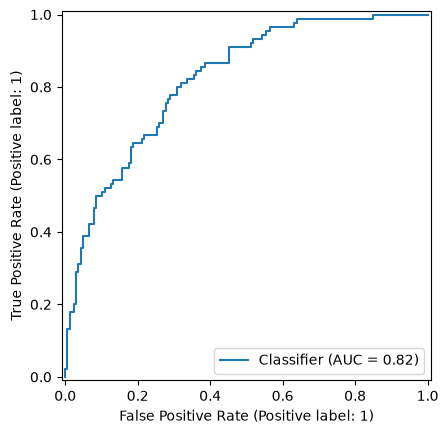

In [429]:
y_positive_prob = logreg.predict_proba(X_test_scaled)[:,1]
auc = roc_auc_score(y_test, y_positive_prob)
RocCurveDisplay.from_predictions(y_test, y_positive_prob)
plt.show()

#### 2.7 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

Use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [accuracy](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules). Feed your scaled X train and y train data.

In [430]:
scores = cross_val_score(logreg, X_train_scaled, y_train, cv=10, scoring='accuracy')

print("Overall performance metric:", scores.mean())

Overall performance metric: 0.7733785822021115


### 3. Use Decision tree classification model to make predictions and evaluate it with above developed functions. Draw ROC curve and compute AUC. Perform k-fold cross-validation.

#### 3.1 Create classification tree object, fit model and generate predictions

In [ ]:
clf = DecisionTreeClassifier(random_state=17)
clf.fit(X_train_scaled, y_train)
y_pred_clf = clf.predict(X_test_scaled)
y_pred_clf[:10]

array([0, 1, 0, 0, 0, 0, 0, 1, 1, 1])

#### 3.2 Evaluate created model with above functions

In [432]:
clf_matrix = confusion_matrix(y_test, y_pred_clf)
clf_matrix

array([[127,  39],
       [ 32,  58]])

In [433]:
tn, fp, fn, tp = clf_matrix.ravel()
print("Accuracy:", accuracy(tp,tn,fp,fn))
print("Precision:", precision(tp,fp))
print("Recall:", recall(tp,fn))
print("Accuracy:", f1(tp,fp,fn))

Accuracy: 58.49609375
Precision: 0.5979381443298969
Recall: 0.6444444444444445
Accuracy: 0.6203208556149733


#### 3.3 Draw a ROC curve and compute Area Under the Curve (AUC)

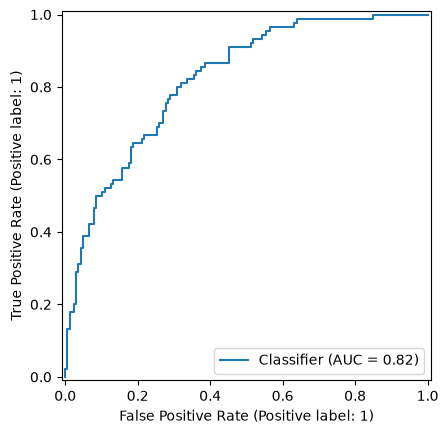

In [434]:
y_positive_prob = logreg.predict_proba(X_test_scaled)[:,1]
auc = roc_auc_score(y_test, y_positive_prob)
RocCurveDisplay.from_predictions(y_test, y_positive_prob)
plt.show()

#### 3.4 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

In [435]:
scores = cross_val_score(clf, X_train_scaled, y_train, cv=10, scoring='accuracy')

print("Overall performance metric:", scores.mean())

Overall performance metric: 0.7091251885369533


#### 3.5 Make conclusions

The both logistic regression and decision tree models performed good and around the same though logistic regression model was a bit better.